In [10]:
import sys
print("Interpretador:", sys.executable)

Interpretador: /Users/lucianarocha/Documents/Faculdade/5ºAno/1ºSemestre/CVC/-CVC-Computer-Vision-Add-ons/.cvc/bin/python


In [11]:
# Clone Github repository
!git clone https://github.com/magicleap/SuperGluePretrainedNetwork.git

# Download and extract HPatches Sequences
!wget https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip
!7z x hpatches-sequences-release.zip

fatal: destination path 'SuperGluePretrainedNetwork' already exists and is not an empty directory.
zsh:1: command not found: wget
zsh:1: command not found: 7z


In [12]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from matplotlib import cm

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "graf").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

GRAF_PATH = PROJECT_ROOT / "graf"

image1_path = GRAF_PATH / "img1.ppm"
image2_path = GRAF_PATH / "img2.ppm"
H12_path = GRAF_PATH / "H1to2p.txt"

print("Project root:", PROJECT_ROOT)
print("GRAF dataset:", GRAF_PATH)

Project root: /Users/lucianarocha/Documents/Faculdade/5ºAno/1ºSemestre/CVC/-CVC-Computer-Vision-Add-ons
GRAF dataset: /Users/lucianarocha/Documents/Faculdade/5ºAno/1ºSemestre/CVC/-CVC-Computer-Vision-Add-ons/graf


In [13]:
image1 = cv2.imread(str(image1_path), cv2.IMREAD_COLOR)
image2 = cv2.imread(str(image2_path), cv2.IMREAD_COLOR)

H = np.loadtxt(H12_path)

assert image1 is not None, f"Could not load {image1_path}"
assert image2 is not None, f"Could not load {image2_path}"
assert H.shape == (3, 3), "Homography must be a 3x3 matrix"

print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)
print("Homography:\n", H)

h1, w1 = image1.shape[:2]
h2, w2 = image2.shape[:2]

Image 1 shape: (320, 400, 3)
Image 2 shape: (320, 400, 3)
Homography:
 [[ 8.7977e-01  3.1245e-01 -1.9715e+01]
 [-1.8389e-01  9.3847e-01  7.6579e+01]
 [ 3.9283e-04 -3.2031e-05  1.0000e+00]]


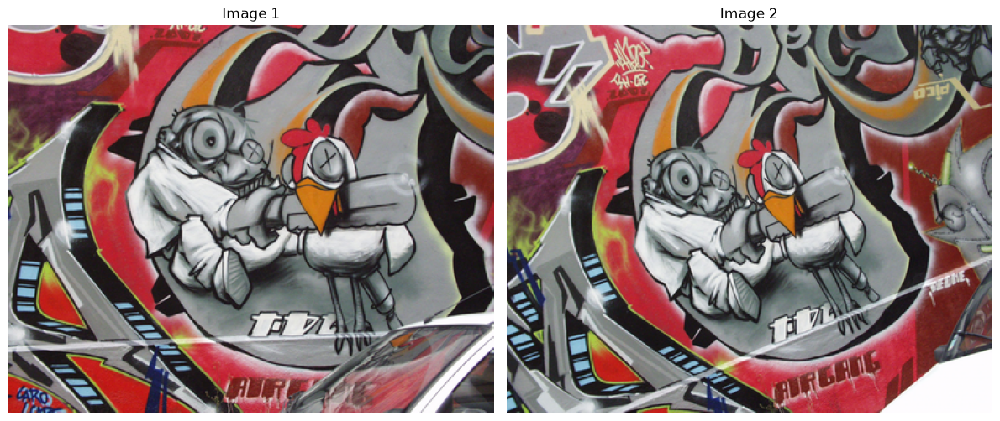

In [14]:
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(image1_rgb)
ax[0].set_title("Image 1")
ax[0].axis("off")

ax[1].imshow(image2_rgb)
ax[1].set_title("Image 2")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### Compreender a homografia através de pontos aleatórios

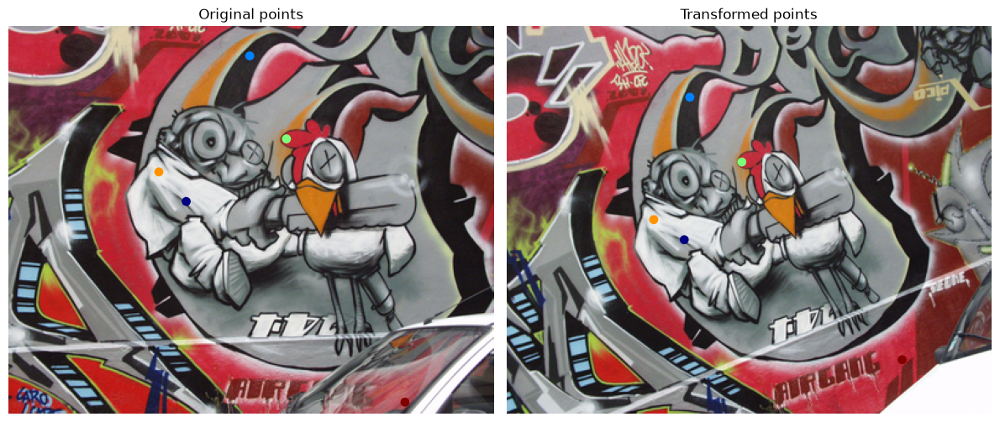

In [15]:
num_points = 5
np.random.seed(58)

pts = np.random.rand(num_points, 2) * np.array([w1, h1])

pts_h = np.hstack([pts, np.ones((num_points, 1))])

pts_t_h = (H @ pts_h.T).T

pts_t = pts_t_h[:, :2] / pts_t_h[:, 2:3]

colors = cm.jet(np.linspace(0, 1, num_points))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(image1_rgb)
ax[0].scatter(pts[:, 0], pts[:, 1], s=45, c=colors)
ax[0].set_title("Original points")
ax[0].axis("off")

ax[1].imshow(image2_rgb)
ax[1].scatter(pts_t[:, 0], pts_t[:, 1], s=45, c=colors)
ax[1].set_title("Transformed points")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### SIFT — Deteção de keypoints e extração de descritores

In [16]:
sift = cv2.SIFT_create()

k1_sift, des1_sift = sift.detectAndCompute(image1, None)
k2_sift, des2_sift = sift.detectAndCompute(image2, None)

print("Image 1 keypoints:", len(k1_sift))
print("Image 2 keypoints:", len(k2_sift))

print("Image 1 descriptor shape:", des1_sift.shape if des1_sift is not None else None)
print("Image 2 descriptor shape:", des2_sift.shape if des2_sift is not None else None)


Image 1 keypoints: 1061
Image 2 keypoints: 1243
Image 1 descriptor shape: (1061, 128)
Image 2 descriptor shape: (1243, 128)


### Visualizar os keypoints SIFT

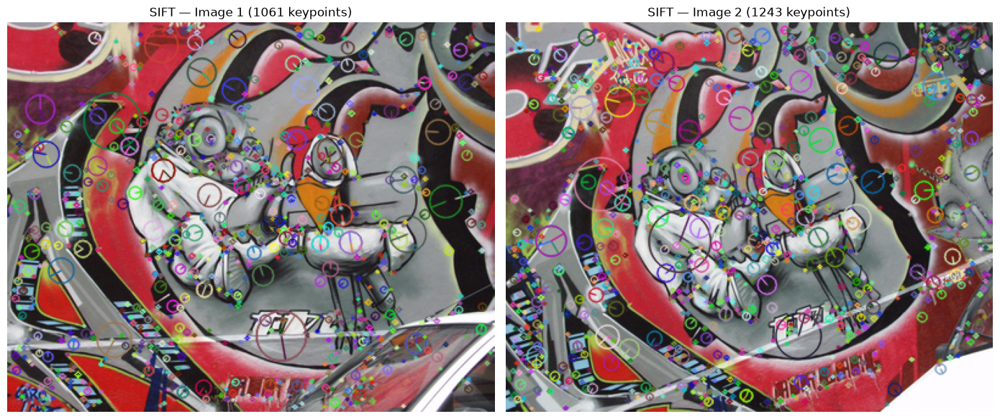

In [17]:
sift_vis1 = cv2.drawKeypoints(
    image1_rgb,
    k1_sift,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_vis2 = cv2.drawKeypoints(
    image2_rgb,
    k2_sift,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(sift_vis1)
ax[0].set_title(f"SIFT — Image 1 ({len(k1_sift)} keypoints)")
ax[0].axis("off")

ax[1].imshow(sift_vis2)
ax[1].set_title(f"SIFT — Image 2 ({len(k2_sift)} keypoints)")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### SIFT — Matching com Brute-Force Matcher

Total SIFT matches: 583


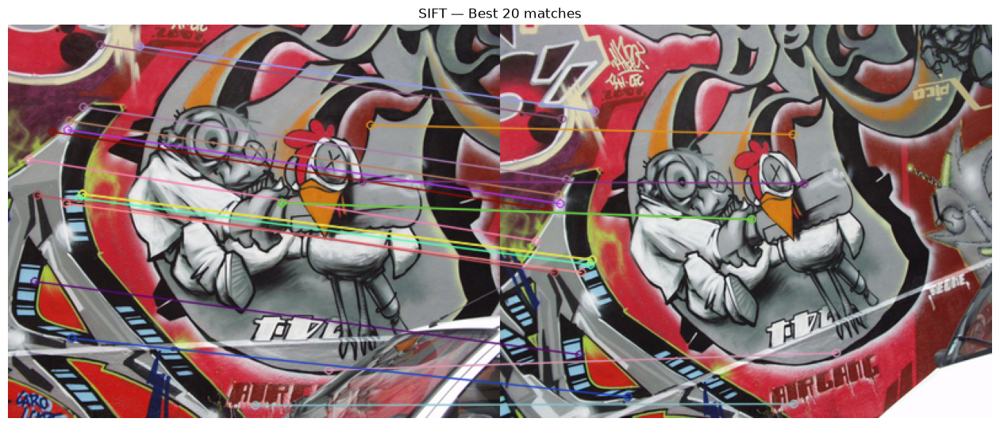

In [18]:
if des1_sift is None or des2_sift is None:
    raise ValueError("SIFT did not produce descriptors for both images.")

bf_sift = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)

matches_sift = bf_sift.match(des1_sift, des2_sift)

matches_sift = sorted(matches_sift, key=lambda m: m.distance)

print("Total SIFT matches:", len(matches_sift))

matches_vis = cv2.drawMatches(
    image1_rgb,
    k1_sift,
    image2_rgb,
    k2_sift,
    matches_sift[:20],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 7))
plt.imshow(matches_vis)
plt.title("SIFT — Best 20 matches")
plt.axis("off")
plt.show()


### FAST — Deteção de keypoints

In [19]:
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

fast = cv2.FastFeatureDetector_create(
    threshold=20,
    nonmaxSuppression=True
)

k1_fast = fast.detect(gray1, None)
k2_fast = fast.detect(gray2, None)

print("FAST threshold:", fast.getThreshold())
print("Non-maximum suppression:", fast.getNonmaxSuppression())
print("FAST type:", fast.getType())
print("Image 1 keypoints:", len(k1_fast))
print("Image 2 keypoints:", len(k2_fast))


FAST threshold: 20
Non-maximum suppression: True
FAST type: 2
Image 1 keypoints: 1869
Image 2 keypoints: 2137


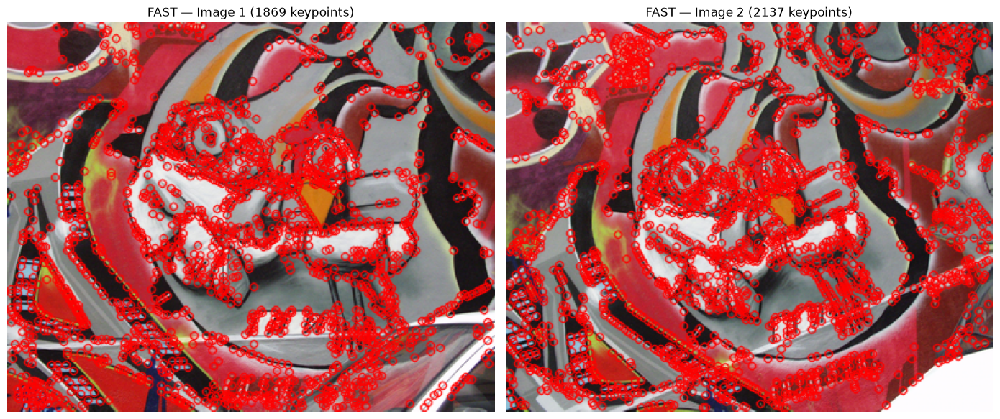

In [20]:
fast_vis1 = cv2.drawKeypoints(
    image1_rgb,
    k1_fast,
    None,
    color=(255, 0, 0)
)

fast_vis2 = cv2.drawKeypoints(
    image2_rgb,
    k2_fast,
    None,
    color=(255, 0, 0)
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(fast_vis1)
ax[0].set_title(f"FAST — Image 1 ({len(k1_fast)} keypoints)")
ax[0].axis("off")

ax[1].imshow(fast_vis2)
ax[1].set_title(f"FAST — Image 2 ({len(k2_fast)} keypoints)")
ax[1].axis("off")

plt.tight_layout()
plt.show()


With non-maximum suppression: 1869
Without non-maximum suppression: 7086


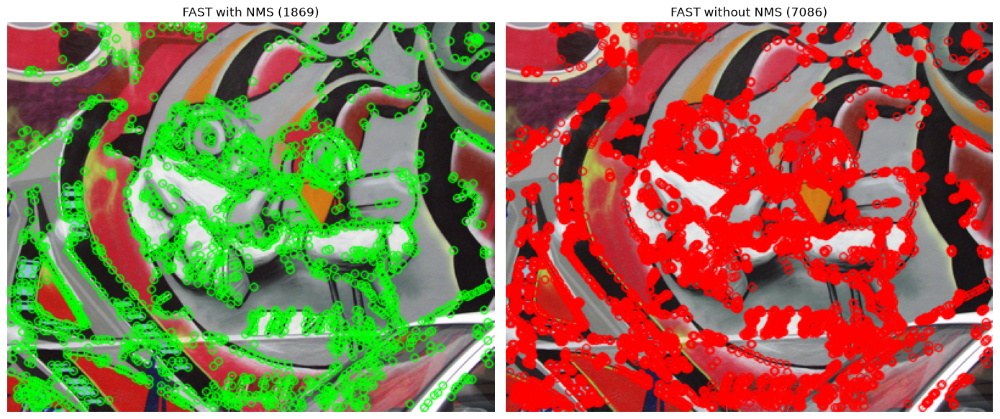

In [21]:

fast_with_nms = cv2.FastFeatureDetector_create(
    threshold=20,
    nonmaxSuppression=True
)

fast_without_nms = cv2.FastFeatureDetector_create(
    threshold=20,
    nonmaxSuppression=False
)

k_with_nms = fast_with_nms.detect(gray1, None)
k_without_nms = fast_without_nms.detect(gray1, None)

print("With non-maximum suppression:", len(k_with_nms))
print("Without non-maximum suppression:", len(k_without_nms))

vis_with_nms = cv2.drawKeypoints(
    image1_rgb,
    k_with_nms,
    None,
    color=(0, 255, 0)
)

vis_without_nms = cv2.drawKeypoints(
    image1_rgb,
    k_without_nms,
    None,
    color=(255, 0, 0)
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(vis_with_nms)
ax[0].set_title(f"FAST with NMS ({len(k_with_nms)})")
ax[0].axis("off")

ax[1].imshow(vis_without_nms)
ax[1].set_title(f"FAST without NMS ({len(k_without_nms)})")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### BRIEF — Descritores binários

In [22]:
if not hasattr(cv2, "xfeatures2d"):
    print("BRIEF is unavailable in this OpenCV installation.")
else:
    brief = cv2.xfeatures2d.BriefDescriptorExtractor_create(
        bytes=32,
        use_orientation=False
    )

    k1_brief, des1_brief = brief.compute(gray1, k1_fast)
    k2_brief, des2_brief = brief.compute(gray2, k2_fast)

    print("Image 1 keypoints with BRIEF:", len(k1_brief))
    print("Image 2 keypoints with BRIEF:", len(k2_brief))

    print(
        "Image 1 descriptor shape:",
        des1_brief.shape if des1_brief is not None else None
    )

    print(
        "Image 2 descriptor shape:",
        des2_brief.shape if des2_brief is not None else None
    )


BRIEF is unavailable in this OpenCV installation.


### BRIEF — Matching com distância Hamming

In [23]:
if (
    "des1_brief" in globals()
    and des1_brief is not None
    and des2_brief is not None
):
    bf_brief = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

    matches_brief = bf_brief.match(des1_brief, des2_brief)
    matches_brief = sorted(matches_brief, key=lambda m: m.distance)

    print("Total FAST + BRIEF matches:", len(matches_brief))

    brief_vis = cv2.drawMatches(
        image1_rgb,
        k1_brief,
        image2_rgb,
        k2_brief,
        matches_brief[:20],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(16, 7))
    plt.imshow(brief_vis)
    plt.title("FAST + BRIEF — Best 20 matches")
    plt.axis("off")
    plt.show()
else:
    print("BRIEF matching skipped because descriptors are unavailable.")


BRIEF matching skipped because descriptors are unavailable.


### FREAK — Descritores binários

In [24]:

if not hasattr(cv2, "xfeatures2d"):
    print("FREAK is unavailable in this OpenCV installation.")
else:
    freak = cv2.xfeatures2d.FREAK_create()

    k1_freak, des1_freak = freak.compute(gray1, k1_fast)
    k2_freak, des2_freak = freak.compute(gray2, k2_fast)

    print("Image 1 keypoints with FREAK:", len(k1_freak))
    print("Image 2 keypoints with FREAK:", len(k2_freak))

    print(
        "Image 1 descriptor shape:",
        des1_freak.shape if des1_freak is not None else None
    )

    print(
        "Image 2 descriptor shape:",
        des2_freak.shape if des2_freak is not None else None
    )


FREAK is unavailable in this OpenCV installation.


In [25]:
if (
    "des1_freak" in globals()
    and des1_freak is not None
    and des2_freak is not None
):
    bf_freak = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

    matches_freak = bf_freak.match(des1_freak, des2_freak)
    matches_freak = sorted(matches_freak, key=lambda m: m.distance)

    print("Total FAST + FREAK matches:", len(matches_freak))

    freak_vis = cv2.drawMatches(
        image1_rgb,
        k1_freak,
        image2_rgb,
        k2_freak,
        matches_freak[:20],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(16, 7))
    plt.imshow(freak_vis)
    plt.title("FAST + FREAK — Best 20 matches")
    plt.axis("off")
    plt.show()
else:
    print("FREAK matching skipped because descriptors are unavailable.")


FREAK matching skipped because descriptors are unavailable.


### Comparação simples dos resultados

In [26]:
results = [
    {
        "Method": "SIFT",
        "Keypoints image 1": len(k1_sift),
        "Keypoints image 2": len(k2_sift),
        "Matches": len(matches_sift)
    },
    {
        "Method": "FAST",
        "Keypoints image 1": len(k1_fast),
        "Keypoints image 2": len(k2_fast),
        "Matches": None
    }
]

if "matches_brief" in globals():
    results.append({
        "Method": "FAST + BRIEF",
        "Keypoints image 1": len(k1_brief),
        "Keypoints image 2": len(k2_brief),
        "Matches": len(matches_brief)
    })

if "matches_freak" in globals():
    results.append({
        "Method": "FAST + FREAK",
        "Keypoints image 1": len(k1_freak),
        "Keypoints image 2": len(k2_freak),
        "Matches": len(matches_freak)
    })

import pandas as pd

pd.DataFrame(results)


,Method,Keypoints image 1,Keypoints image 2,Matches
0,SIFT,1061,1243,583.0
1,FAST,1869,2137,NaN
